# 06 · Bayesian models

Needs `pip install "checkmodel[bayes]"` (PyMC, bambi; Python 3.12+). A bambi multilevel model of the `sleepstudy` data, checked like any other model. Sampling takes a minute.

In [1]:
import sys

DATA = "../tests/data"
if "google.colab" in sys.modules:  # on Colab: install checkmodel, read the data from GitHub
    %pip install -q "checkmodel[bayes]"
    DATA = "https://raw.githubusercontent.com/pablo-legeren/checkmodel/main/tests/data"

In [2]:
import warnings

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore", category=FutureWarning)
import bambi as bmb

sleep = pd.read_csv(f"{DATA}/sleepstudy.csv")
model = bmb.Model("Reaction ~ Days + (Days|Subject)", sleep)
idata = model.fit(draws=500, tune=500, chains=2, cores=1, random_seed=1, progressbar=False)

g++ not available, if using conda: `conda install gxx`


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [sigma, Intercept, Days, 1|Subject_sigma, 1|Subject_offset, Days|Subject_sigma, Days|Subject_offset]


Sampling 2 chains for 500 tune and 500 draw iterations (1_000 + 1_000 draws total) took 21 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


`bayesian()` gathers what checkmodel needs; with bambi it also computes expected values, posterior predictive draws and the pointwise log-likelihood.

In [3]:
from checkmodel import bayesian, check_model

fit = bayesian(idata, model)
report = check_model(fit)
report

# Model checks: bambi (gaussian, identity link), n = 180

Posterior predictive check: OK: Model-predicted data resemble the observed data (mean p = 0.481, sd p = 0.530).
Convergence: OK: Chains converged (max R-hat = 1.006, min bulk ESS = 452).

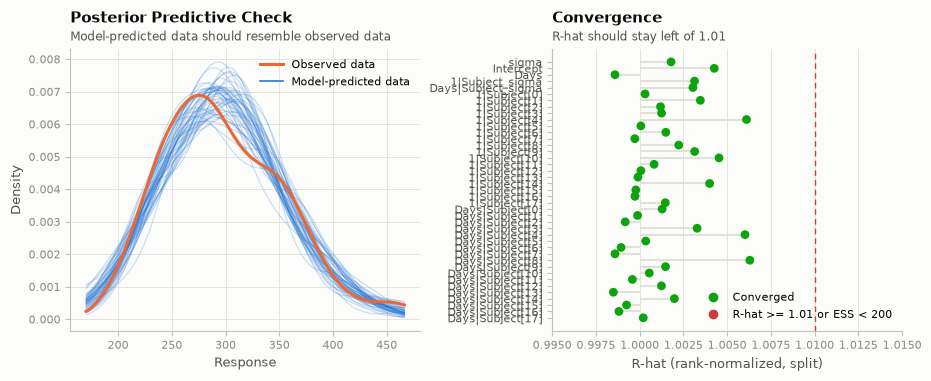

In [4]:
report.plot();

## Bayesian R² and leave-one-out cross-validation

In [5]:
from checkmodel import looic, model_performance, r2_bayes

r2_bayes(fit)

# Bayesian R2 with Compatibility Interval

  Conditional R2: 0.795 (95% CI [0.766, 0.827])
     Marginal R2: 0.280 (95% CI [0.157, 0.410])

In [6]:
model_performance(fit)

,ELPD,ELPD_SE,LOOIC,LOOIC_SE,WAIC,R2,R2_marginal,RMSE,Sigma
0,-858.781283,22.186226,1717.562567,44.372452,1717.077185,0.795408,0.279835,23.373774,25.677109


In [7]:
loo = looic(fit)
loo.elpd_loo, loo.n_bad_k

(-858.7812833808762, 2)

## Convergence diagnostics

Rank-normalized R-hat and bulk/tail effective sample sizes per parameter, as R's `posterior` package computes them.

In [8]:
from checkmodel import check_convergence

check_convergence(fit).to_dataframe().round(3)

,Parameter,Rhat,ESS_bulk,ESS_tail
0,sigma,1.002,947.092,595.671
1,Intercept,1.004,777.248,607.260
2,Days,0.999,451.713,567.908
3,1|Subject_sigma,1.003,531.830,629.727
4,Days|Subject_sigma,1.003,477.279,589.589
5,1|Subject[0],1.000,1427.404,876.227
6,1|Subject[1],1.003,1427.939,823.504
7,1|Subject[2],1.001,1203.817,570.027
8,1|Subject[3],1.001,1434.842,754.044
9,1|Subject[4],1.006,1172.444,726.723
